# Model Training and Evaluation

The dataset is divided into two subsets using an 80/20 stratified split:

- Training set (8,000 observations): Used to train the classification models, perform cross-validation and optimise hyperparameters.
- Test set (2,000 observations): Used for initial evaluations of model performance on observations not included in training.

Stratification preserves the original proportion of machine failures (approximately 3.4%) in both subsets, ensuring that the relatively rare failure cases are represented consistently.

As the test set was examined during the initial exploratory evaluations, it is not treated as a completely untouched final test set. The reported cross-validation results are therefore interpreted with appropriate caution.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_recall_curve, precision_score, recall_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("../data/ai4i2020.csv")

# Exclude identifiers and failure-mode indicators
excluded_columns = [
    "UDI", "Product ID", "Machine failure",
    "TWF", "HDF", "PWF", "OSF", "RNF",
]

X = df.drop(columns=excluded_columns)
y = df["Machine failure"]

# Encode the categorical machine type
X = pd.get_dummies(X, columns=["Type"], dtype=int)

# Preserve class proportions in the train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Training failure rate:", round(y_train.mean() * 100, 2), "%")
print("Testing failure rate:", round(y_test.mean() * 100, 2), "%")


Training observations: 8000
Testing observations: 2000
Training failure rate: 3.39 %
Testing failure rate: 3.4 %


## 2. Baseline Model

A majority-class classifier is used to establish baseline performance.

Machine failures are relatively rare, making this an imbalanced classification problem. Consequently, accuracy alone may be misleading when assessing model performance.

Four metrics are used throughout the analysis:

- Accuracy: The proportion of all observations classified correctly. A model can achieve high accuracy simply by predicting that no failures occur.

- Precision: The proportion of predicted failures that are genuine failures. Higher precision indicates fewer unnecessary maintenance warnings.

- Recall: The proportion of actual failures correctly identified. Higher recall indicates that fewer genuine failures are missed.

- F1-score: The harmonic mean of precision and recall, providing a combined measure of failure detection and false alarms.

The confusion matrix is also used to examine true positives, true negatives, false positives and false negatives.

F1-score is used as the primary metric for model comparison due to the class imbalance, although recall and precision remain important when considering the practical consequences of incorrect predictions.


In [2]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

print("Baseline performance:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_baseline):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_baseline, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_baseline):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_baseline):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_baseline))


Baseline performance:
Accuracy:  0.9660
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000

Confusion matrix:
[[1932    0]
 [  68    0]]


## 3. Logistic Regression

Logistic Regression provides an interpretable linear classification model against which more flexible machine learning algorithms can be compared. Numerical features are standardised within a training pipeline to account for differences in measurement scales.

In [3]:
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

logistic_model.fit(X_train, y_train)

y_pred_logistic = logistic_model.predict(X_test)

print("Logistic Regression performance:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_logistic):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_logistic):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_logistic):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_logistic):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_logistic))


Logistic Regression performance:
Accuracy:  0.8250
Precision: 0.1421
Recall:    0.8235
F1-score:  0.2424

Confusion matrix:
[[1594  338]
 [  12   56]]


### Initial Model Comparison

The majority-class baseline achieved 96.6% accuracy but failed to identify any machine failures, demonstrating why accuracy is insufficient for evaluating an imbalanced classification problem.

Logistic Regression, using balanced class weights, identified 56 of the 68 failures in the test dataset, achieving 82.35% recall.

However, it also generated 338 false positives, resulting in precision of only 14.21%. This demonstrates a substantial trade-off between identifying failures and avoiding unnecessary warnings.

Further modelling will investigate whether non-linear classification algorithms can improve this balance.


## 4. Decision Tree

Decision Trees classify observations using a sequence of decision rules based on input features. Unlike basic Logistic Regression, they can represent non-linear relationships and interactions between operating conditions.

### Investigating Decision Tree Depth

The maximum depth of a Decision Tree controls its complexity. Shallower trees produce simpler decision rules, while deeper trees can capture more detailed relationships between operating conditions.

However, increasing tree depth can also lead to overfitting, where the model learns patterns specific to the training data rather than relationships that generalise to unseen observations.

To investigate this, Decision Trees with maximum depths of 5, 10 and 20 are compared using stratified five-fold cross-validation. Precision, recall and F1-score are evaluated to assess how increasing complexity affects failure detection.


In [18]:
tree_model = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

tree_model.fit(X_train, y_train)

y_pred_tree = tree_model.predict(X_test)

print("Decision Tree performance:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_tree):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_tree):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_tree):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_tree):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_tree))


Decision Tree performance:
Accuracy:  0.9295
Precision: 0.3109
Recall:    0.8824
F1-score:  0.4598

Confusion matrix:
[[1799  133]
 [   8   60]]


In [19]:
tree_depth_results = []

for depth in [5, 10, 20]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        class_weight="balanced",
        random_state=42
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["precision", "recall", "f1"],
        n_jobs=-1
    )

    tree_depth_results.append({
        "Max Depth": depth,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean()
    })

tree_depth_df = pd.DataFrame(tree_depth_results)

display(tree_depth_df.round(4))


,Max Depth,Precision,Recall,F1-score
0,5,0.3038,0.8600,0.4485
1,10,0.4518,0.6386,0.5255
2,20,0.6937,0.5647,0.6187


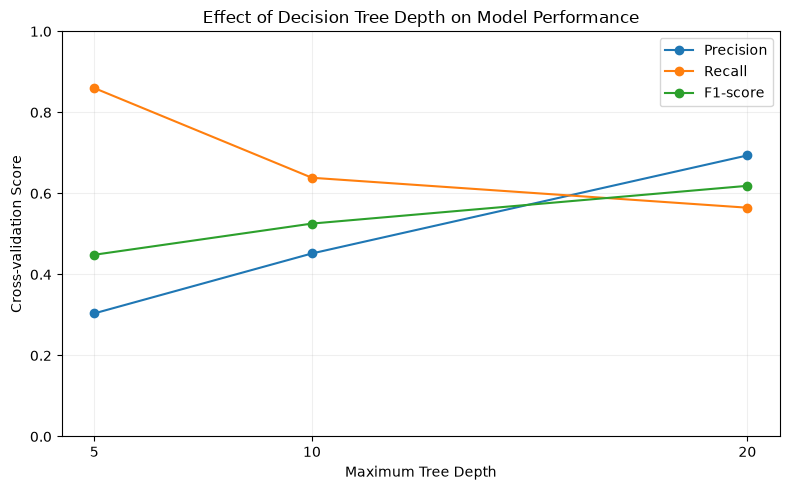

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))

for metric in ["Precision", "Recall", "F1-score"]:
    ax.plot(
        tree_depth_df["Max Depth"],
        tree_depth_df[metric],
        marker="o",
        label=metric
    )

ax.set_xlabel("Maximum Tree Depth")
ax.set_ylabel("Cross-validation Score")
ax.set_title("Effect of Decision Tree Depth on Model Performance")
ax.set_xticks([5, 10, 20])
ax.set_ylim(0, 1)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


### Decision Tree Results and Depth Analysis

The initial Decision Tree (`max_depth=5`) achieved 92.95% accuracy, 31.09% precision, 88.24% recall and an F1-score of 45.98% on the test dataset.

Compared with Logistic Regression, it correctly identified four additional failures while reducing false positives from 338 to 133. This suggests that modelling non-linear relationships and interactions between operating conditions may improve classification performance. However, the remaining false positives demonstrate the need to balance failure detection against unnecessary maintenance warnings.

#### Effect of Maximum Tree Depth

Increasing the maximum depth produced substantial changes in classification performance:

- Depth 5: Achieved the highest recall (86.00%) but relatively low precision (30.38%) and F1-score (44.85%). This configuration identified most failures but generated many false alarms.
- Depth 10: Improved precision to 45.18% and F1-score to 52.55%, while recall decreased to 63.86%.
- Depth 20: Achieved the highest precision (69.37%) and F1-score (61.87%), although recall decreased further to 56.47%.

These results demonstrate a clear trade-off between precision and recall. Shallower trees detected more genuine failures but produced more false alarms, whereas deeper trees reduced false alarms but failed to detect a greater proportion of actual failures.

Although deeper trees are generally more susceptible to overfitting, the cross-validation results alone do not establish whether overfitting occurred. Comparing training and validation performance would provide further insight.

#### Model Selection

The depth-5 Decision Tree was retained as the original recall-oriented configuration for subsequent model comparisons. Its ability to identify a high proportion of failures may be valuable in applications where missed failures are particularly costly.

However, depth 20 achieved the highest F1-score among the configurations tested and is also included in the final model comparison to provide a more complete assessment.

The appropriate configuration ultimately depends on the relative importance of detecting failures and minimising false alarms.


## 5. Random Forest

Random Forest combines predictions from multiple decision trees to improve robustness and capture complex relationships between operating conditions.

In [30]:
forest_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, y_train)

y_pred_forest = forest_model.predict(X_test)

print("Random Forest performance:")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_forest):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_forest):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_forest):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_forest):.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred_forest))


Random Forest performance:
Accuracy:  0.9555
Precision: 0.4234
Recall:    0.8529
F1-score:  0.5659

Confusion matrix:
[[1853   79]
 [  10   58]]


### Random Forest Results

The initial Random Forest achieved 95.55% accuracy, 42.34% precision, 85.29% recall and an F1-score of 56.59% on the test dataset.

The model correctly identified 58 of the 68 actual failures, missing 10 and generating 79 false positives.

Compared with the depth-5 Decision Tree, Random Forest reduced false positives from 133 to 79, although it identified two fewer genuine failures. Precision increased from 31.09% to 42.34%, while recall decreased from 88.24% to 85.29%.

The higher F1-score (56.59% compared with 45.98%) indicates that Random Forest achieved a better overall balance between precision and recall, although the Decision Tree remained more effective at detecting genuine failures.

These results demonstrate the trade-off between reducing unnecessary maintenance warnings and identifying machine failures. Further evaluation using cross-validation and hyperparameter optimisation is required to assess whether the Random Forest's performance can be improved.

## 6. Cross-Validation

The initial models were evaluated using a single 80/20 training-test split. However, performance on one test set may depend on which observations happen to be included, particularly when machine failures account for only 3.4% of the dataset.

To obtain a more reliable comparison, stratified five-fold cross-validation is applied to the 8,000 training observations.

### Method

The training dataset is divided into five approximately equal folds, each containing around 1,600 observations.

For each of the five iterations:

1. The model is trained using four folds (approximately 6,400 observations).
2. Predictions are made on the remaining fold (approximately 1,600 observations), which was not used to train that model.
3. Precision, recall and F1-score are calculated using these predictions.
4. The process is repeated with a different fold used for validation.

Each observation is therefore used for validation exactly once, and the five resulting scores are averaged to estimate model performance.

Stratification ensures that each fold contains approximately the same proportion of machine failures as the overall training dataset. This is particularly important given the substantial class imbalance.

The original 2,000 test observations are excluded from this procedure.

### Evaluation

The mean precision, recall and F1-score are calculated across the five folds. The standard deviation of F1-score is also recorded to assess how much performance varies between validation subsets.

F1-score is used as the primary comparison metric because it combines precision and recall, although both individual metrics remain important when considering the consequences of false alarms and missed failures.

Cross-validation provides a more robust basis for comparing the initial models than relying on a single data split. It also supports subsequent hyperparameter optimisation by allowing different model configurations to be evaluated consistently.

However, cross-validation does not guarantee performance on completely unseen data. Furthermore, selecting model configurations based on their cross-validation results can produce optimistic performance estimates, which should be considered when interpreting the final results.


In [31]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["precision", "recall", "f1"],
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(3))


,Model,Precision,Recall,F1-score,F1 Std
0,Logistic Regression,0.137,0.804,0.235,0.010
1,Decision Tree,0.304,0.860,0.449,0.009
2,Random Forest,0.446,0.782,0.568,0.024



## 7. Feature Importance

Permutation importance is used to investigate which input variables contribute most to the Random Forest model's predictions.

Each feature is shuffled independently, and the resulting change in F1-score is measured. Features causing the largest performance reductions are considered most influential for the model.

This is calculated on the training data and may overstate generalisable importance; correlated features may share predictive information.


In [7]:
importance = permutation_importance(
    forest_model,
    X_train,
    y_train,
    scoring="f1",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": importance.importances_mean,
    "Std": importance.importances_std
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))


,Feature,Importance,Std
2,Rotational speed [rpm],0.2298,0.0098
3,Torque [Nm],0.2265,0.0121
4,Tool wear [min],0.1877,0.0089
0,Air temperature [K],0.1605,0.0054
1,Process temperature [K],0.0331,0.0068
5,Type_H,0.0004,0.0034
6,Type_L,-0.0076,0.0021
7,Type_M,-0.0189,0.0024


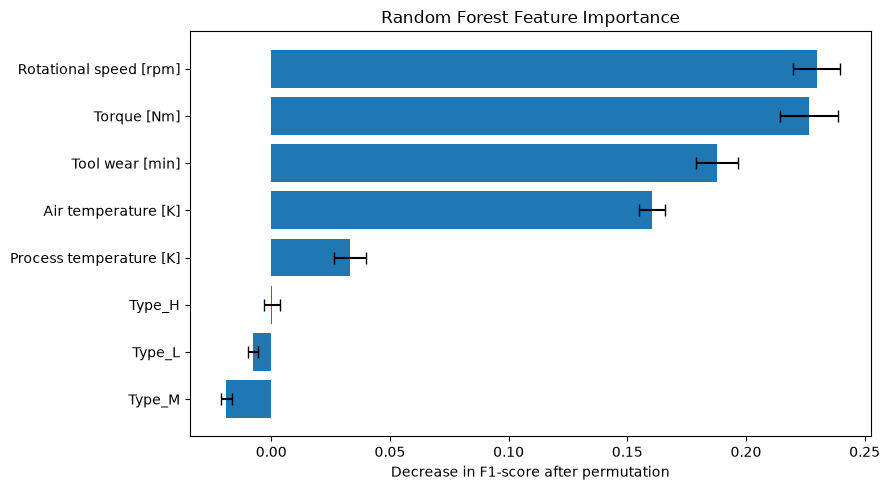

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Std"],
    capsize=4
)

ax.invert_yaxis()

ax.set_xlabel("Decrease in F1-score after permutation")
ax.set_title("Random Forest Feature Importance")

plt.tight_layout()
plt.savefig("../figures/feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()



## 8. Hyperparameter Optimisation

RandomizedSearchCV is used to explore different Random Forest configurations, with stratified five-fold cross-validation.

The search aims to maximise F1-score while monitoring the balance between precision and recall. All tuning is performed using the training dataset to avoid further influencing model development using the held-out test set.


In [32]:
# Define the settings to explore
param_distributions = {
    "n_estimators": np.arange(100, 401, 50),
    "max_depth": list(np.arange(4, 21, 2)) + [None],
    "min_samples_split": [2, 3, 5, 10, 15, 20],
    "min_samples_leaf": [1, 2, 3, 4, 5, 8, 10],
    "max_features": ["sqrt", "log2", None],
    "class_weight": ["balanced", "balanced_subsample", None]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

search = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ),
    param_distributions=param_distributions,
    n_iter=100,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1"
    },
    refit="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:")
print(search.best_params_)

print(f"\nBest cross-validation F1: {search.best_score_:.4f}")


Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best parameters:
{'n_estimators': np.int64(200), 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': np.int64(10), 'class_weight': None}

Best cross-validation F1: 0.7609


In [33]:
results_df = pd.DataFrame(search.cv_results_)

comparison = results_df[[
    "mean_test_precision",
    "mean_test_recall",
    "mean_test_f1",
    "std_test_f1",
    "params"
]].sort_values("mean_test_f1", ascending=False)

display(comparison.head(10).round(4))


,mean_test_precision,mean_test_recall,mean_test_f1,std_test_f1,params
24,0.8693,0.6789,0.7609,0.0274,"{'n_estimators': 200, 'min_samples_split': 10,..."
48,0.8547,0.6863,0.7590,0.0480,"{'n_estimators': 100, 'min_samples_split': 10,..."
0,0.8756,0.6677,0.7551,0.0455,"{'n_estimators': 150, 'min_samples_split': 3, ..."
61,0.8655,0.6678,0.7506,0.0437,"{'n_estimators': 200, 'min_samples_split': 15,..."
92,0.8649,0.6566,0.7433,0.0576,"{'n_estimators': 250, 'min_samples_split': 5, ..."
38,0.8664,0.6421,0.7351,0.0510,"{'n_estimators': 100, 'min_samples_split': 2, ..."
11,0.8547,0.6457,0.7327,0.0554,"{'n_estimators': 250, 'min_samples_split': 20,..."
66,0.6942,0.7638,0.7253,0.0266,"{'n_estimators': 350, 'min_samples_split': 10,..."
34,0.8522,0.6127,0.7109,0.0469,"{'n_estimators': 400, 'min_samples_split': 2, ..."
78,0.8588,0.6017,0.7055,0.0491,"{'n_estimators': 300, 'min_samples_split': 10,..."


In [36]:
print("Best hyperparameters:")

for parameter, value in search.best_params_.items():
    print(f"{parameter}: {value}")

print(f"\nBest cross-validation F1-score: {search.best_score_:.4f}")


Best hyperparameters:
n_estimators: 200
min_samples_split: 10
min_samples_leaf: 2
max_features: None
max_depth: 10
class_weight: None

Best cross-validation F1-score: 0.7609



### Hyperparameter Optimisation Results

RandomizedSearchCV evaluated 100 Random Forest configurations using stratified five-fold cross-validation, selecting the configuration with the highest mean F1-score.

The best-performing configuration used 200 trees, a maximum depth of 10, a minimum of 10 observations to split a node, at least two observations per leaf, all features available at each split, and no class weighting.

This configuration achieved a mean cross-validation precision of 0.869, recall of 0.679 and F1-score of 0.761, compared with an F1-score of 0.568 for the initial Random Forest.

The improvement was primarily associated with substantially higher precision, while recall decreased moderately. This indicates fewer false alarms but a greater proportion of missed failures.

Notably, the selected configuration did not use class weighting, despite the substantial class imbalance. This demonstrates the importance of evaluating modelling choices empirically rather than assuming that particular settings will always improve performance.

However, the selected cross-validation score may be optimistic because the best configuration was chosen from 100 candidates evaluated on the same folds.


## 9. Classification Threshold Analysis

Out-of-fold predicted probabilities are used to investigate the trade-off between precision and recall at different classification thresholds.

Threshold selection is performed using training data only.
The F1-maximising threshold is estimated using pooled out-of-fold predictions; its selected score is optimistic, and the default 0.5 threshold remains a simpler choice.

In [37]:
best_forest = search.best_estimator_

# Each observation is predicted by a model that did not train on it
cv_probabilities = cross_val_predict(
    best_forest,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_train,
    cv_probabilities
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print(f"Best threshold: {best_threshold:.3f}")
print(f"Precision: {precision[best_index]:.3f}")
print(f"Recall: {recall[best_index]:.3f}")
print(f"F1-score: {f1_scores[best_index]:.3f}")


Best threshold: 0.457
Precision: 0.848
Recall: 0.701
F1-score: 0.768


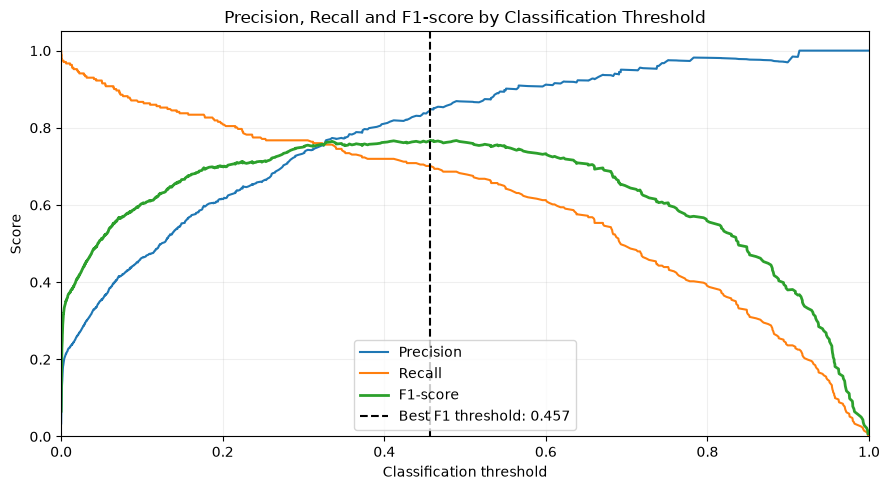

In [39]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(thresholds, precision[:-1], label="Precision")
ax.plot(thresholds, recall[:-1], label="Recall")
ax.plot(thresholds, f1_scores, label="F1-score", linewidth=2)

ax.axvline(
    best_threshold,
    linestyle="--",
    color="black",
    label=f"Best F1 threshold: {best_threshold:.3f}"
)

ax.set_xlabel("Classification threshold")
ax.set_ylabel("Score")
ax.set_title("Precision, Recall and F1-score by Classification Threshold")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig("../figures/threshold_analysis.png", dpi=300, bbox_inches="tight")
plt.show()


### Classification Threshold Results

Classification threshold analysis was performed using out-of-fold predicted probabilities from the optimised Random Forest.

The F1-maximising threshold was identified as 0.457, producing a precision of 0.848, recall of 0.701 and F1-score of 0.768.

Reducing the classification threshold below the default value of 0.5 increased the proportion of genuine failures detected, although this came at the expense of a small reduction in precision.

The improvement in F1-score was relatively modest, suggesting that the default threshold already provided a reasonable balance between precision and recall.

This analysis demonstrates how classification thresholds can be adjusted to reflect different operational priorities. In applications where missed failures are particularly costly, a lower threshold may be preferred even if it reduces overall precision or F1-score.

The selected threshold was optimised using cross-validated training predictions, so its reported performance may be optimistic and should not be interpreted as an independent estimate of generalisation performance.

## 10. Final Model Comparison

The baseline classifier, Logistic Regression, Decision Tree, original Random Forest and optimised Random Forest are compared using stratified five-fold cross-validation.

Precision, recall and F1-score are reported to account for the substantial class imbalance in the dataset.

The optimised Random Forest is evaluated at the default classification threshold of 0.5. Its hyperparameters were selected using the same cross-validation procedure, so its performance estimate may be optimistic.

In [40]:
# Collect the models we have developed
final_models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": logistic_model,
    "Decision Tree (depth 5)": tree_model,
    "Decision Tree (depth 20)": DecisionTreeClassifier(
        max_depth=20,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": forest_model,
    "Optimised Random Forest": search.best_estimator_
}


# Evaluate every model using the same five folds
comparison_results = []

for name, model in final_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        },
        n_jobs=-1
    )

    comparison_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-score": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std()
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))


/Users/matthew/Documents/Coding Projects/predictive-maintenance-ml/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/matthew/Documents/Coding Projects/predictive-maintenance-ml/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/Users/matthew/Documents/Coding Projects/predictive-maintenance-ml/.venv/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zer

,Model,Accuracy,Precision,Recall,F1-score,F1 Std
0,Baseline,0.9661,0.0000,0.0000,0.0000,0.0000
1,Logistic Regression,0.8225,0.1374,0.8044,0.2346,0.0098
2,Decision Tree (depth 5),0.9284,0.3038,0.8600,0.4485,0.0093
3,Decision Tree (depth 20),0.9766,0.6937,0.5647,0.6187,0.0430
4,Random Forest,0.9596,0.4465,0.7822,0.5681,0.0240
5,Optimised Random Forest,0.9856,0.8693,0.6789,0.7609,0.0274


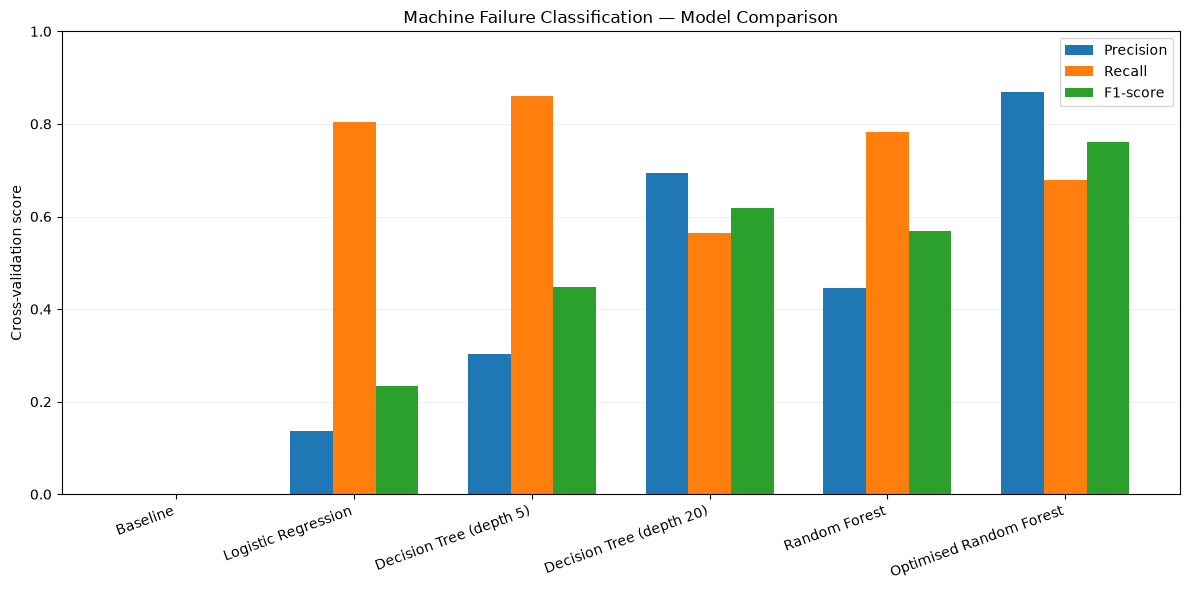

In [41]:
metrics = ["Precision", "Recall", "F1-score"]

x = np.arange(len(comparison_df))
width = 0.24

fig, ax = plt.subplots(figsize=(12, 6))

for i, metric in enumerate(metrics):
    ax.bar(
        x + (i - 1) * width,
        comparison_df[metric],
        width,
        label=metric
    )

ax.set_xticks(x)
ax.set_xticklabels(
    comparison_df["Model"],
    rotation=20,
    ha="right"
)

ax.set_ylabel("Cross-validation score")
ax.set_ylim(0, 1)
ax.set_title("Machine Failure Classification — Model Comparison")

ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("../figures/model_comparison.png", dpi=300, bbox_inches="tight")
plt.show()



## Model Comparison and Discussion

The baseline classifier achieved 96.61% accuracy by predicting that no machines would fail. However, its precision, recall and F1-score were all zero, demonstrating why accuracy alone is misleading for this imbalanced dataset.

Logistic Regression achieved relatively high recall (0.804) but low precision (0.137), indicating that it identified many genuine failures while generating numerous false alarms.

The depth-5 Decision Tree achieved the highest recall (0.860) of all configurations, but its relatively low precision (0.304) indicated a substantial number of incorrect failure warnings. Increasing tree depth to 20 improved precision to 0.694 and F1-score to 0.619, although recall decreased to 0.565.

The initial Random Forest achieved an F1-score of 0.568, providing a better balance between precision and recall than the depth-5 Decision Tree.

Following hyperparameter optimisation, the Random Forest achieved the highest mean cross-validation F1-score (0.761), alongside precision of 0.869 and recall of 0.679. This represented a substantial improvement in precision over the initial configuration, although a smaller proportion of actual failures were identified.

Classification threshold analysis subsequently identified an F1-maximising threshold of 0.457, producing an exploratory F1-score of 0.768 using pooled out-of-fold predictions.

### Practical Implications

These results demonstrate that model selection depends on the relative consequences of false positives and false negatives.

The optimised Random Forest provides the strongest overall balance according to F1-score, while the depth-5 Decision Tree identifies the greatest proportion of failures.

In an industrial setting, missed failures may result in expensive repairs and unplanned downtime, whereas false alarms could lead to unnecessary inspections. A model prioritising recall may therefore be preferable when missed failures are substantially more costly, even if its F1-score is lower.

### Limitations

The dataset contains synthetic machine-failure outcomes, so the results do not demonstrate performance on real industrial equipment. Furthermore, the analysis classifies simulated failure conditions rather than predicting the remaining useful life of machinery.

The optimised Random Forest's cross-validation performance may also be optimistic because its hyperparameters were selected using the same validation folds. The test dataset was examined during initial model development and therefore cannot be considered a completely untouched final evaluation set.

Additional validation on independent data would be necessary before drawing conclusions about real-world deployment.
